# English → Hindi Machine Translation: Transformer vs mT5 vs LLaMA vs Gemma
**Course:** Foundations of Generative AI (ICT4403) - Assignment 3

| System | Architecture | Adaptation |
|---|---|---|
| Basic Transformer | encoder-decoder | trained **from scratch** |
| mT5-small | encoder-decoder | **fine-tuned** (pretrained multilingual) |
| Llama-3.2-1B-Instruct | decoder-only | **few-shot prompting** and **LoRA fine-tuning** |
| Gemma-3-1B-it | decoder-only | **few-shot prompting** and **LoRA fine-tuning** |

All systems translate the **same held-out test sentences** with the **same decoding rule (greedy)** for the main comparison.
Quality is measured with BLEU and chrF (sacreBLEU); cost with training time, inference time and parameter counts.
A temperature sweep and a responsible-AI analysis follow.

**How to run:** Google Colab (Runtime -> Change runtime type -> **T4 GPU** -> Run all) **or Kaggle** (Settings -> Accelerator **GPU**, Internet **On**, then Run All or *Save Version -> Save & Run All*). About 1.5-2.5 hours.
A Hugging Face token is optional (see the login note below). Each system saves its result to `results/*.json`,
so if the session disconnects you can re-run and finished systems are skipped.

## 0. Setup

In [1]:
import os, sys, re, json, time, math, random, shutil, subprocess, collections
SMOKE = bool(os.environ.get("SMOKE"))   # internal wiring test only (synthetic data + tiny random models). Never set on Colab.
ON_COLAB = "google.colab" in sys.modules
ON_KAGGLE = os.path.exists("/kaggle/working")
if (ON_COLAB or ON_KAGGLE) and not SMOKE:     # install / upgrade the libraries this notebook needs (Gemma 3 needs a recent transformers)
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"])   # Kaggle ships an old torchao that makes peft crash (needs >=0.16); it is not needed here
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U",
                        "sacrebleu", "sentencepiece", "peft", "datasets", "accelerate", "transformers"])
    print("pip install finished, return code", r.returncode, "(dependency-conflict warnings above are normal)")
if ON_KAGGLE and not SMOKE:
    os.chdir("/kaggle/working")                # outputs written here appear in the notebook's Output tab
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sacrebleu, transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup
try:
    from transformers.optimization import Adafactor
except Exception:
    from torch.optim import Adafactor

transformers.logging.set_verbosity_error()      # hides the very repetitive generate() warnings
import traceback, hashlib
FAILED = []
def attempt(name, fn):
    # Run one system; if it crashes, print the error and carry on with the next one (finished systems are saved to results/).
    try: fn()
    except Exception:
        print(f"\n!!! {name} FAILED - continuing with the next system. Fix the error and run again; finished systems are skipped.\n"); traceback.print_exc(); FAILED.append(name)
        import gc; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
BF16_OK = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8
for d in ["data", "results", "plots", "samples"]:
    os.makedirs(d, exist_ok=True)
if ON_KAGGLE and not SMOKE:     # RESUME: if you attached an earlier run's results as a Kaggle Dataset (Add Input), reuse the finished systems
    KNOWN = ["Transformer_scratch.json", "mT5_small_fine_tuned.json", "Llama_3_2_1B_few_shot.json", "Llama_3_2_1B_LoRA.json", "Gemma_3_1B_few_shot.json", "Gemma_3_1B_LoRA.json"]
    for root, _, files in os.walk("/kaggle/input"):
        for fn in files:
            if fn in KNOWN: shutil.copy(os.path.join(root, fn), "results/" + fn); print("restored", fn)
            elif fn.startswith("translations_") and fn.endswith(".tsv"): shutil.copy(os.path.join(root, fn), "samples/" + fn)
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device:", GPU_NAME, "| bf16:", BF16_OK)
if DEVICE == "cpu" and not SMOKE:
    print("WARNING: no GPU detected. Runtime -> Change runtime type -> T4 GPU, then re-run.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


pip install finished, return code 0 (dependency-conflict warnings above are normal)
torch 2.11.0+cu128 | transformers 5.22.0 | device: Tesla T4 | bf16: False


### Hugging Face login (optional)
Llama and Gemma are "gated" on Hugging Face. **You can skip login entirely:** the notebook then uses the ungated `unsloth/...` re-uploads of the same weights.
To use the official repositories instead: (1) accept the licences on `meta-llama/Llama-3.2-1B-Instruct` and `google/gemma-3-1b-it`; (2) create a free **read** token;
(3) store it as a secret named `HF_TOKEN` (Kaggle: *Add-ons -> Secrets*; Colab: the key icon in the left sidebar, notebook access ON). The next cell picks it up automatically.

If access to a gated model is not granted yet, the notebook automatically falls back to the ungated `unsloth/...` re-upload of the
**same weights** and prints which repository it used. Report that in your README.

In [2]:
HF_TOKEN = None
if not SMOKE:
    try:                                           # Kaggle: Add-ons -> Secrets -> label HF_TOKEN
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception: pass
    if HF_TOKEN is None:
        try:                                       # Colab: key icon (Secrets) -> name HF_TOKEN, notebook access ON
            from google.colab import userdata
            HF_TOKEN = userdata.get("HF_TOKEN")
        except Exception: pass
    if HF_TOKEN:
        from huggingface_hub import login
        login(token=HF_TOKEN); print("Logged in to Hugging Face with the HF_TOKEN secret.")
    else:
        print("No HF_TOKEN secret found: continuing WITHOUT login. The ungated unsloth copies of the same Llama / Gemma weights will be used.")

No HF_TOKEN secret found: continuing WITHOUT login. The ungated unsloth copies of the same Llama / Gemma weights will be used.


## 1. Configuration (identical data and decoding for every system)

In [3]:
CFG = dict(
    n_train=50_000, n_val=500, n_test=500, n_temp=100, max_words=40,
    sp_vocab=8000, tf_d=256, tf_heads=4, tf_layers=3, tf_ff=1024, tf_drop=0.1, tf_bs=64, tf_epochs=15, tf_lr=7e-4, tf_warm=1000, tf_maxlen=64,
    mt5_id="google/mt5-small", mt5_bs=16, mt5_epochs=2, mt5_lr=1e-3, mt5_maxlen=64,
    llama_ids=["meta-llama/Llama-3.2-1B-Instruct", "unsloth/Llama-3.2-1B-Instruct"],
    gemma_ids=["google/gemma-3-1b-it", "unsloth/gemma-3-1b-it"],
    lora_train=10_000, lora_r=16, lora_alpha=32, lora_lr=2e-4, lora_epochs=1, lora_maxlen=192,
    llama_bs=8, llama_accum=2, gemma_bs=4, gemma_accum=4,
    gen_bs=16, max_new=128, temps=[0.3, 0.7, 1.0], n_shots=3,
)
if SMOKE:
    CFG.update(n_train=600, n_val=40, n_test=24, n_temp=12, sp_vocab=120, tf_d=64, tf_heads=2, tf_layers=2, tf_ff=128, tf_bs=32,
               tf_epochs=14, tf_warm=20, mt5_epochs=1, mt5_bs=16, lora_train=96, llama_bs=8, llama_accum=1, gemma_bs=8, gemma_accum=1,
               gen_bs=8, max_new=24)
print(json.dumps(CFG, indent=1))

{
 "n_train": 50000,
 "n_val": 500,
 "n_test": 500,
 "n_temp": 100,
 "max_words": 40,
 "sp_vocab": 8000,
 "tf_d": 256,
 "tf_heads": 4,
 "tf_layers": 3,
 "tf_ff": 1024,
 "tf_drop": 0.1,
 "tf_bs": 64,
 "tf_epochs": 15,
 "tf_lr": 0.0007,
 "tf_warm": 1000,
 "tf_maxlen": 64,
 "mt5_id": "google/mt5-small",
 "mt5_bs": 16,
 "mt5_epochs": 2,
 "mt5_lr": 0.001,
 "mt5_maxlen": 64,
 "llama_ids": [
  "meta-llama/Llama-3.2-1B-Instruct",
  "unsloth/Llama-3.2-1B-Instruct"
 ],
 "gemma_ids": [
  "google/gemma-3-1b-it",
  "unsloth/gemma-3-1b-it"
 ],
 "lora_train": 10000,
 "lora_r": 16,
 "lora_alpha": 32,
 "lora_lr": 0.0002,
 "lora_epochs": 1,
 "lora_maxlen": 192,
 "llama_bs": 8,
 "llama_accum": 2,
 "gemma_bs": 4,
 "gemma_accum": 4,
 "gen_bs": 16,
 "max_new": 128,
 "temps": [
  0.3,
  0.7,
  1.0
 ],
 "n_shots": 3
}


## 2. Dataset: description and pre-processing
**Primary dataset:** the IIT Bombay English-Hindi parallel corpus (`cfilt/iitb-english-hindi` on Hugging Face), about 1.6 million sentence pairs
from government, news and web sources, with an official dev and test split. If it cannot be loaded, the notebook falls back to
OPUS-100 English-Hindi (`Helsinki-NLP/opus-100`, config `en-hi`). Because of the compute limits of a free GPU, a **manageable random subset** is used
(`n_train` training pairs, `n_val` validation, `n_test` test), as the assignment allows.

Pre-processing: strip whitespace; keep pairs whose English and Hindi sides have 3-40 words, a plausible length ratio, Hindi text that is mostly
Devanagari and English text with no Devanagari; remove exact duplicates; remove any training pair whose English sentence also occurs in validation or test (no leakage).

In [4]:
DEV = re.compile(r"[ऀ-ॿ]"); LAT = re.compile(r"[A-Za-z]")

def synthetic_pairs(n, seed):
    EN = "the a man woman child dog cat house book water food tree river sun moon sees likes has eats reads big small red green old new".split()
    HI = ["वह","एक","आदमी","औरत","बच्चा","कुत्ता","बिल्ली","घर","किताब","पानी","खाना","पेड़","नदी","सूरज","चाँद","देखता","पसंद","है","खाता","पढ़ता","बड़ा","छोटा","लाल","हरा","पुराना","नया"]
    assert len(EN) == len(HI)
    m = dict(zip(EN, HI)); rng = random.Random(seed); out = []
    for _ in range(n):
        ws = [rng.choice(EN) for _ in range(rng.randint(4, 9))]
        out.append((" ".join(ws), " ".join(m[w] for w in ws)))
    return out

def load_parallel():
    if SMOKE:
        return dict(train=synthetic_pairs(4000, 1), validation=synthetic_pairs(300, 2), test=synthetic_pairs(300, 3)), "synthetic (smoke test)"
    from datasets import load_dataset
    attempts = [("cfilt/iitb-english-hindi", (), {}),
                ("cfilt/iitb-english-hindi", (), {"revision": "refs/convert/parquet"}),
                ("Helsinki-NLP/opus-100", ("en-hi",), {})]
    last = None
    for path, args, kw in attempts:
        try:
            ds = load_dataset(path, *args, **kw)
            def grab(split, n, seed):
                d = ds[split]
                if n is not None:
                    d = d.shuffle(seed=seed).select(range(min(n, len(d))))
                return [(r["en"], r["hi"]) for r in d["translation"]]
            raw = dict(train=grab("train", 4 * CFG["n_train"], SEED), validation=grab("validation", None, SEED), test=grab("test", None, SEED))
            return raw, path + (" " + str(kw) if kw else "")
        except Exception as e:
            print("could not load", path, kw, "->", type(e).__name__, str(e)[:120]); last = e
    raise RuntimeError("No parallel dataset could be loaded") from last

def ok_pair(en, hi):
    ne, nh = len(en.split()), len(hi.split())
    if not (3 <= ne <= CFG["max_words"] and 3 <= nh <= int(CFG["max_words"] * 1.6)): return False
    if not 0.5 <= nh / ne <= 2.2: return False
    dev, lat = len(DEV.findall(hi)), len(LAT.findall(hi))
    if dev == 0 or dev / (dev + lat) < 0.7: return False
    if DEV.search(en) or not LAT.search(en): return False
    return True

def clean(pairs):
    seen, out = set(), []
    for en, hi in pairs:
        en, hi = " ".join(en.split()), " ".join(hi.split())
        k = en.lower()
        if k in seen or not ok_pair(en, hi): continue
        seen.add(k); out.append((en, hi))
    return out

raw, DATASET_USED = load_parallel()
print("Dataset used:", DATASET_USED, "| raw sizes:", {k: len(v) for k, v in raw.items()})
rng = random.Random(SEED)
val_all, test_all = clean(raw["validation"]), clean(raw["test"])
rng.shuffle(val_all); rng.shuffle(test_all)
val, test = val_all[:CFG["n_val"]], test_all[:CFG["n_test"]]
heldout = {en.lower() for en, _ in val_all + test_all}
train_all = [p for p in clean(raw["train"]) if p[0].lower() not in heldout]
rng.shuffle(train_all)
train = train_all[:CFG["n_train"]]
train_src, train_tgt = [p[0] for p in train], [p[1] for p in train]
val_src, val_tgt = [p[0] for p in val], [p[1] for p in val]
test_src, test_tgt = [p[0] for p in test], [p[1] for p in test]
for name, d in [("train", train), ("val", val), ("test", test)]:
    with open(f"data/{name}.tsv", "w", encoding="utf-8") as f:
        f.writelines(f"{a}\t{b}\n" for a, b in d)
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  190MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.7kB            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1659083 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/520 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2507 [00:00<?, ? examples/s]

Dataset used: cfilt/iitb-english-hindi | raw sizes: {'train': 200000, 'validation': 520, 'test': 2507}
train 50,000 | val 500 | test 500


{
  "dataset": "cfilt/iitb-english-hindi",
  "train_pairs": 50000,
  "val_pairs": 500,
  "test_pairs": 500,
  "avg_en_words": 14.92,
  "avg_hi_words": 16.27,
  "en_word_types": 66732,
  "hi_word_types": 70703
}

Examples:
 EN: South Asian Association for Regional Cooperation (SAARC) (External website that opens in a new window) 
 HI: दक्षिण एशिया क्षेत्रीय सहयोग संगठन (सार्क) (बाहरी वेबसाइट जो एक नई विंडों में खुलती हैं) 

 EN: I 've set G54 X and Y values, now I' m going to set Z 
 HI: मैं G54 X और Y मान, स्थापित किया है अब मैं Z सेट करने के लिए जा रहा हूँ 

 EN: Hyder Buz Jatoi wrote his Address or Apostrophe to the river of the Sindhis in the 'twenties. 
 HI: हैदरबख्श जतोई ने सिंधु को संबोधित करने वाली यह कविता तीसरे दशकमें लिखी थी। 

 EN: RAID ARRAY IS MISCONFIGURED RAID 
 HI: सरणी कुविन्यस्त है 

 EN: Is it magic, or you cannot see? 
 HI: "अब भला (बताओ) यह कोई जादू है या तुम्हे सुझाई नहीं देता? 



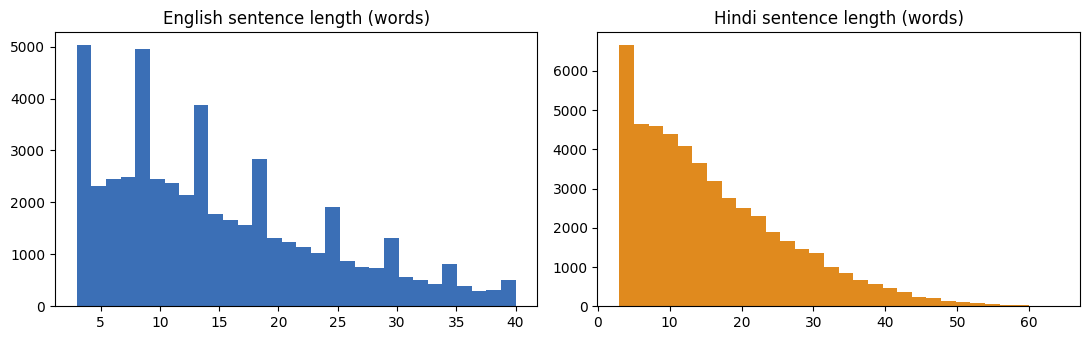

In [5]:
ne = [len(s.split()) for s in train_src]; nh = [len(t.split()) for t in train_tgt]
stats = dict(dataset=DATASET_USED, train_pairs=len(train), val_pairs=len(val), test_pairs=len(test),
             avg_en_words=round(float(np.mean(ne)), 2), avg_hi_words=round(float(np.mean(nh)), 2),
             en_word_types=len({w.lower() for s in train_src for w in s.split()}), hi_word_types=len({w for t in train_tgt for w in t.split()}))
json.dump(stats, open("results/dataset_stats.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(stats, indent=2, ensure_ascii=False))
print("\nExamples:")
for s, t in train[:5]: print(" EN:", s, "\n HI:", t, "\n")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(ne, bins=30, color="#3b6fb6"); ax[0].set_title("English sentence length (words)")
ax[1].hist(nh, bins=30, color="#e08a1e"); ax[1].set_title("Hindi sentence length (words)")
plt.tight_layout(); plt.savefig("plots/01_dataset_lengths.png", dpi=130); plt.show()

## 3. Shared utilities: metrics, timing, parameter counts, result storage, evaluation harness
* **BLEU** and **chrF** from sacreBLEU (`corpus_bleu`, `corpus_chrf`) against the single reference.
* **Inference time**: wall-clock time to translate the full test set (greedy, batched); also reported as ms per sentence.
* **Parameters**: total and trainable (LoRA trains only the adapter weights).
* Every system is evaluated by the same function `evaluate_system`, which also runs the temperature sweep and the responsible-AI probe sentences, and saves everything to `results/<system>.json`.

In [6]:
def sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

def score(hyps, refs):
    return sacrebleu.corpus_bleu(hyps, [refs]).score, sacrebleu.corpus_chrf(hyps, [refs]).score

def count_params(m):
    tot = sum(p.numel() for p in m.parameters()); tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return tot, tr

def make_batches(lengths, bs, seed):
    rng = random.Random(seed); idx = list(range(len(lengths))); rng.shuffle(idx); out = []
    for i in range(0, len(idx), bs * 50):
        c = sorted(idx[i:i + bs * 50], key=lambda j: lengths[j])
        out += [c[k:k + bs] for k in range(0, len(c), bs)]
    rng.shuffle(out); return out

def free_gpu():
    import gc; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()

# Probe sentences for the responsible-AI analysis (section 9)
PROBES = [
    ("gender / occupation", "The nurse told the engineer that she would be late."),
    ("gender / occupation", "The doctor asked the nurse to help him with the patient."),
    ("gender / occupation", "My boss is a very strong leader and my secretary is very helpful."),
    ("idiom", "It is raining cats and dogs, so let us stay inside."),
    ("idiom", "After a long illness the old man finally kicked the bucket."),
    ("politeness / honorifics", "Could you please help me, sir? I would be very grateful."),
    ("cultural / religious", "Please remove your shoes before entering the temple."),
    ("cultural / religious", "The festival of lights is celebrated with sweets and prayers."),
    ("medical (sensitive)", "Take two tablets every six hours and do not exceed eight tablets in a day."),
    ("medical (sensitive)", "The patient should avoid this medicine during pregnancy."),
    ("legal / violence (sensitive)", "The mob attacked the village at night and several people were injured."),
    ("legal / violence (sensitive)", "The court ordered the accused to stay away from the victim."),
    ("numbers / entities", "The meeting is on 14 March 2025 at 5:30 pm in Mumbai with Dr. Rao."),
    ("numbers / entities", "Transfer 25,000 rupees to account number 1234 before Friday."),
    ("short / ambiguous", "Yes."),
    ("short / ambiguous", "Thank you very much."),
]

TEST_SIG = hashlib.md5("\n".join(test_src).encode("utf-8")).hexdigest()
def result_path(name): return f"results/{re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_')}.json"
def load_result(name):
    p = result_path(name)
    if not os.path.exists(p): return None
    r = json.load(open(p, encoding="utf-8"))
    if r.get("test_sig") not in (None, TEST_SIG):
        print(f"WARNING: saved result for {name} was made on a different test set - ignoring it and re-running."); return None
    return r

def evaluate_system(name, translate, params_total, params_trainable, train_time, extra=None):
    '''translate(list_of_sources, temperature) -> list_of_hypotheses  (temperature 0 = greedy)'''
    sync(); t0 = time.time(); hyps = translate(test_src, 0.0); sync(); infer = time.time() - t0
    bleu, chrf = score(hyps, test_tgt)
    n = CFG["n_temp"]
    temp_rows = [dict(temperature="greedy", bleu=score(hyps[:n], test_tgt[:n])[0], chrf=score(hyps[:n], test_tgt[:n])[1])]
    for T in CFG["temps"]:
        h = translate(test_src[:n], T); b, c = score(h, test_tgt[:n])
        temp_rows.append(dict(temperature=T, bleu=b, chrf=c, sample=h[:3]))
    probes = translate([p[1] for p in PROBES], 0.0)
    res = dict(system=name, bleu=bleu, chrf=chrf, params_total=params_total, params_trainable=params_trainable,
               train_time_s=train_time, infer_time_s=infer, ms_per_sentence=1000 * infer / len(test_src),
               hardware=GPU_NAME, test_sig=TEST_SIG, hyps=hyps, temperature_sweep=temp_rows, probes=probes, extra=extra or {})
    json.dump(res, open(result_path(name), "w", encoding="utf-8"), indent=1, ensure_ascii=False)
    with open("samples/translations_" + re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_") + ".tsv", "w", encoding="utf-8") as f:
        f.write("source\treference\thypothesis\n"); f.writelines(f"{s}\t{r}\t{h}\n" for s, r, h in zip(test_src, test_tgt, hyps))
    print(f"[{name}] BLEU {bleu:.2f} | chrF {chrf:.2f} | train {train_time:.0f}s | infer {infer:.1f}s ({res['ms_per_sentence']:.0f} ms/sent) | params {params_total/1e6:.1f}M (trainable {params_trainable/1e6:.2f}M)")
    for s, h, r in list(zip(test_src, hyps, test_tgt))[:3]: print("  EN :", s, "\n  OUT:", h, "\n  REF:", r)
    return res

## 4. System 1: Basic Transformer (encoder-decoder, trained from scratch)
A small standard Transformer (3 encoder + 3 decoder layers, d_model 256, 4 heads, feed-forward 1024, pre-layer-norm, shared source/target embeddings tied to the output layer).
Tokenisation: a joint **SentencePiece BPE** model (vocab 8,000) trained only on the training data. Loss: cross-entropy with label smoothing 0.1; AdamW with warm-up and inverse-square-root decay.
The model starts with **no pretraining**, so with only 50k sentence pairs it is expected to be the weakest system. That is a finding, not a bug.

In [7]:
import sentencepiece as spm
with open("data/sp_train.txt", "w", encoding="utf-8") as f:
    for s, t in zip(train_src, train_tgt): f.write(s + "\n" + t + "\n")
spm.SentencePieceTrainer.train(input="data/sp_train.txt", model_prefix="data/sp", vocab_size=CFG["sp_vocab"], model_type="bpe",
                               character_coverage=1.0, pad_id=0, unk_id=1, bos_id=2, eos_id=3, hard_vocab_limit=False, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file="data/sp.model")
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPV = sp.get_piece_size()
print("SentencePiece vocab:", SPV, "| example:", sp.encode(train_src[0], out_type=str)[:12])

class PosEnc(nn.Module):
    def __init__(self, d, p, maxlen=512):
        super().__init__()
        pe = torch.zeros(maxlen, d); pos = torch.arange(maxlen).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0)); self.drop = nn.Dropout(p)
    def forward(self, x): return self.drop(x + self.pe[:, :x.size(1)])

class Seq2SeqTransformer(nn.Module):
    def __init__(self, V, d, h, L, ff, p):
        super().__init__()
        self.d = d; self.emb = nn.Embedding(V, d, padding_idx=PAD); self.pos = PosEnc(d, p)
        self.tf = nn.Transformer(d, h, L, L, ff, p, batch_first=True, norm_first=True)
        self.out = nn.Linear(d, V, bias=False); self.out.weight = self.emb.weight   # tied embeddings
        for prm in self.tf.parameters():
            if prm.dim() > 1: nn.init.xavier_uniform_(prm)
        nn.init.normal_(self.emb.weight, mean=0.0, std=d ** -0.5)    # small init: the weight is tied to the output layer (N(0,1) gives huge logits)
        with torch.no_grad(): self.emb.weight[PAD].zero_()
    def encode(self, src):
        mask = src == PAD
        return self.tf.encoder(self.pos(self.emb(src) * math.sqrt(self.d)), src_key_padding_mask=mask), mask
    def decode(self, tgt, mem, mem_mask):
        T = tgt.size(1); causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt.device), 1)
        h = self.tf.decoder(self.pos(self.emb(tgt) * math.sqrt(self.d)), mem, tgt_mask=causal, memory_key_padding_mask=mem_mask)
        return self.out(h)
    def forward(self, src, tgt_in):
        mem, mm = self.encode(src); return self.decode(tgt_in, mem, mm)

def tf_encode_pairs(srcs, tgts):
    ex = []
    for s, t in zip(srcs, tgts):
        a = sp.encode(s)[:CFG["tf_maxlen"] - 1] + [EOS]; b = sp.encode(t)[:CFG["tf_maxlen"] - 1]
        ex.append((a, [BOS] + b, b + [EOS]))
    return ex

def tf_collate(ex, idx):
    def pad(seqs):
        L = max(len(s) for s in seqs); return torch.tensor([s + [PAD] * (L - len(s)) for s in seqs])
    return [pad([ex[i][k] for i in idx]).to(DEVICE) for k in range(3)]

def train_transformer():
    set_seed()
    model = Seq2SeqTransformer(SPV, CFG["tf_d"], CFG["tf_heads"], CFG["tf_layers"], CFG["tf_ff"], CFG["tf_drop"]).to(DEVICE)
    tr, va = tf_encode_pairs(train_src, train_tgt), tf_encode_pairs(val_src, val_tgt)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["tf_lr"], betas=(0.9, 0.98), weight_decay=0.01)
    lossf = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)
    step, hist, best, best_state = 0, [], 1e9, None; t_train = 0.0
    lens = [len(e[0]) + len(e[1]) for e in tr]
    for ep in range(1, CFG["tf_epochs"] + 1):
        model.train(); sync(); t0 = time.time(); run = n = 0
        for idx in make_batches(lens, CFG["tf_bs"], SEED + ep):
            step += 1
            for g in opt.param_groups: g["lr"] = CFG["tf_lr"] * min(step / CFG["tf_warm"], math.sqrt(CFG["tf_warm"] / step))
            src, tin, tout = tf_collate(tr, idx)
            loss = lossf(model(src, tin).reshape(-1, SPV), tout.reshape(-1))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            run += loss.item(); n += 1
        sync(); t_train += time.time() - t0
        model.eval(); vl = vn = 0
        with torch.no_grad():
            vlens = [len(e[0]) + len(e[1]) for e in va]
            for idx in make_batches(vlens, 64, 0):
                src, tin, tout = tf_collate(va, idx); vl += lossf(model(src, tin).reshape(-1, SPV), tout.reshape(-1)).item(); vn += 1
        vl /= max(vn, 1); hist.append(dict(epoch=ep, train_loss=run / n, val_loss=vl))
        print(f"[Transformer] epoch {ep}/{CFG['tf_epochs']}  train_loss {run/n:.3f}  val_loss {vl:.3f}  elapsed {t_train:.0f}s")
        if vl < best: best, best_state = vl, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, hist, t_train

@torch.no_grad()
def tf_translate(model, srcs, T=0.0, bs=64, max_len=96, seed=0):
    model.eval(); g = torch.Generator(device=DEVICE).manual_seed(seed)
    order = sorted(range(len(srcs)), key=lambda i: -len(srcs[i])); out = [None] * len(srcs)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        src = tf_collate([(sp.encode(srcs[j])[:CFG["tf_maxlen"] - 1] + [EOS], [], []) for j in idx], range(len(idx)))[0]
        mem, mm = model.encode(src); ys = torch.full((len(idx), 1), BOS, device=DEVICE); done = torch.zeros(len(idx), dtype=torch.bool, device=DEVICE)
        for _ in range(max_len):
            logits = model.decode(ys, mem, mm)[:, -1]; logits[:, [PAD, UNK, BOS]] = -float("inf")
            if T > 0: nxt = torch.multinomial(F.softmax(logits / T, -1), 1, generator=g).squeeze(1)
            else: nxt = logits.argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD), nxt); ys = torch.cat([ys, nxt[:, None]], 1); done |= nxt == EOS
            if done.all(): break
        for k, j in enumerate(idx):
            ids = [t for t in ys[k, 1:].tolist() if t not in (PAD,)]
            if EOS in ids: ids = ids[:ids.index(EOS)]
            out[j] = sp.decode(ids)
    return out

NAME_TF = "Transformer (scratch)"
def run_tf():
    if load_result(NAME_TF) is not None: print("already done, loaded from results/ :", NAME_TF); return
    tf_model, tf_hist, tf_time = train_transformer()
    p_tot, p_tr = count_params(tf_model)
    evaluate_system(NAME_TF, lambda s, T: tf_translate(tf_model, s, T), p_tot, p_tr, tf_time, extra=dict(history=tf_hist))
    del tf_model; free_gpu()
attempt(NAME_TF, run_tf)

SentencePiece vocab: 8000 | example: ['▁South', '▁As', 'ian', '▁As', 'soci', 'ation', '▁for', '▁Reg', 'ional', '▁Co', 'operation', '▁(']


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


[Transformer] epoch 1/15  train_loss 7.053  val_loss 6.257  elapsed 38s
[Transformer] epoch 2/15  train_loss 5.670  val_loss 5.607  elapsed 76s
[Transformer] epoch 3/15  train_loss 5.114  val_loss 5.369  elapsed 116s
[Transformer] epoch 4/15  train_loss 4.821  val_loss 5.223  elapsed 154s
[Transformer] epoch 5/15  train_loss 4.617  val_loss 5.140  elapsed 193s
[Transformer] epoch 6/15  train_loss 4.464  val_loss 5.060  elapsed 232s
[Transformer] epoch 7/15  train_loss 4.341  val_loss 5.000  elapsed 271s
[Transformer] epoch 8/15  train_loss 4.242  val_loss 4.975  elapsed 311s
[Transformer] epoch 9/15  train_loss 4.156  val_loss 4.937  elapsed 350s
[Transformer] epoch 10/15  train_loss 4.082  val_loss 4.905  elapsed 389s
[Transformer] epoch 11/15  train_loss 4.018  val_loss 4.881  elapsed 428s
[Transformer] epoch 12/15  train_loss 3.960  val_loss 4.859  elapsed 467s
[Transformer] epoch 13/15  train_loss 3.908  val_loss 4.857  elapsed 506s
[Transformer] epoch 14/15  train_loss 3.862  val_

## 5. System 2: mT5-small (encoder-decoder, fine-tuned)
`google/mt5-small` (about 300M parameters, most of them in the 250k-token multilingual embedding table) is pretrained on mC4 in 101 languages with a span-corruption objective.
It is **fine-tuned** on the same training pairs using the task prefix `translate English to Hindi: `. Adafactor (lr 1e-3, constant) in **fp32**, because mT5 is unstable in fp16.

In [8]:
PREFIX = "translate English to Hindi: "

def toy_tokenizer():
    from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
    from transformers import PreTrainedTokenizerFast
    tk = Tokenizer(models.BPE(unk_token="<unk>")); tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False); tk.decoder = decoders.ByteLevel()
    tr = trainers.BpeTrainer(vocab_size=500, special_tokens=["<pad>", "<unk>", "<bos>", "<eos>"], initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tk.train_from_iterator([PREFIX + s for s in train_src] + train_tgt + [p[1] for p in PROBES] + ["Translate the following sentence from English to Hindi.\nEnglish: Hindi:"], tr)
    return PreTrainedTokenizerFast(tokenizer_object=tk, pad_token="<pad>", unk_token="<unk>", bos_token="<bos>", eos_token="<eos>")

def load_mt5():
    if SMOKE:
        from transformers import T5Config, T5ForConditionalGeneration
        tok = toy_tokenizer(); cfg = T5Config(vocab_size=len(tok), d_model=64, d_ff=128, d_kv=16, num_layers=2, num_heads=4,
                                              pad_token_id=0, eos_token_id=3, decoder_start_token_id=0)
        return T5ForConditionalGeneration(cfg).to(DEVICE), tok
    tok = AutoTokenizer.from_pretrained(CFG["mt5_id"])
    return AutoModelForSeq2SeqLM.from_pretrained(CFG["mt5_id"]).to(DEVICE), tok

def s2s_batch(tok, srcs, tgts):
    enc = tok([PREFIX + s for s in srcs], max_length=CFG["mt5_maxlen"], truncation=True, padding=True, return_tensors="pt")
    lab = tok(text_target=tgts, max_length=CFG["mt5_maxlen"] + 32, truncation=True, padding=True, return_tensors="pt")["input_ids"]
    lab[lab == tok.pad_token_id] = -100
    return enc.to(DEVICE), lab.to(DEVICE)

def finetune_mt5(model, tok):
    set_seed(); model.train()
    opt = Adafactor(model.parameters(), lr=CFG["mt5_lr"], relative_step=False, scale_parameter=False, warmup_init=False)
    lens = [len(s) for s in train_src]; hist = []; t_train = 0.0
    for ep in range(1, CFG["mt5_epochs"] + 1):
        model.train(); sync(); t0 = time.time(); run = n = 0
        for idx in make_batches(lens, CFG["mt5_bs"], SEED + ep):
            enc, lab = s2s_batch(tok, [train_src[i] for i in idx], [train_tgt[i] for i in idx])
            loss = model(**enc, labels=lab).loss
            if not torch.isfinite(loss): continue
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            run += loss.item(); n += 1
            if n % 500 == 0: print(f"  [mT5] ep {ep} step {n} loss {run/n:.3f}  elapsed {t_train + time.time() - t0:.0f}s")
        sync(); t_train += time.time() - t0
        model.eval(); vl = vn = 0
        with torch.no_grad():
            for i in range(0, len(val_src), 32):
                enc, lab = s2s_batch(tok, val_src[i:i + 32], val_tgt[i:i + 32]); vl += model(**enc, labels=lab).loss.item(); vn += 1
        hist.append(dict(epoch=ep, train_loss=run / max(n, 1), val_loss=vl / max(vn, 1)))
        print(f"[mT5] epoch {ep}/{CFG['mt5_epochs']}  train_loss {run/max(n,1):.3f}  val_loss {vl/max(vn,1):.3f}  elapsed {t_train:.0f}s")
    return hist, t_train

@torch.no_grad()
def s2s_translate(model, tok, srcs, T=0.0, bs=32, max_new=96, seed=0):
    model.eval(); torch.manual_seed(seed)
    order = sorted(range(len(srcs)), key=lambda i: -len(srcs[i])); out = [None] * len(srcs)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        enc = tok([PREFIX + srcs[j] for j in idx], max_length=CFG["mt5_maxlen"], truncation=True, padding=True, return_tensors="pt").to(DEVICE)
        kw = dict(max_new_tokens=max_new, do_sample=T > 0)
        if T > 0: kw.update(temperature=T, top_k=0, top_p=1.0)
        dec = tok.batch_decode(model.generate(**enc, **kw), skip_special_tokens=True)
        for k, j in enumerate(idx): out[j] = dec[k].strip()
    return out

NAME_MT5 = "mT5-small (fine-tuned)"
def run_mt5():
    if load_result(NAME_MT5) is not None: print("already done, loaded from results/ :", NAME_MT5); return
    mt5, mt5_tok = load_mt5()
    mt5_hist, mt5_time = finetune_mt5(mt5, mt5_tok)
    p_tot, p_tr = count_params(mt5)
    evaluate_system(NAME_MT5, lambda s, T: s2s_translate(mt5, mt5_tok, s, T), p_tot, p_tr, mt5_time, extra=dict(history=mt5_hist))
    del mt5; free_gpu()
attempt(NAME_MT5, run_mt5)

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

...

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.20GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

  [mT5] ep 1 step 500 loss 4.194  elapsed 279s
  [mT5] ep 1 step 1000 loss 3.738  elapsed 546s
  [mT5] ep 1 step 1500 loss 3.519  elapsed 815s
  [mT5] ep 1 step 2000 loss 3.370  elapsed 1082s
  [mT5] ep 1 step 2500 loss 3.260  elapsed 1351s
  [mT5] ep 1 step 3000 loss 3.171  elapsed 1622s
[mT5] epoch 1/2  train_loss 3.152  val_loss 2.550  elapsed 1691s
  [mT5] ep 2 step 500 loss 2.535  elapsed 1960s
  [mT5] ep 2 step 1000 loss 2.513  elapsed 2229s
  [mT5] ep 2 step 1500 loss 2.498  elapsed 2500s
  [mT5] ep 2 step 2000 loss 2.478  elapsed 2772s
  [mT5] ep 2 step 2500 loss 2.457  elapsed 3036s
  [mT5] ep 2 step 3000 loss 2.441  elapsed 3311s
[mT5] epoch 2/2  train_loss 2.437  val_loss 2.360  elapsed 3377s
[mT5-small (fine-tuned)] BLEU 5.89 | chrF 25.71 | train 3377s | infer 18.4s (37 ms/sent) | params 300.2M (trainable 300.18M)
  EN : This will solve the drinking water problem of the devotees. 
  OUT: यह दर्शकों के पानी की समस्या को हल करेगा। 
  REF: जिससे आने जाने वाले श्रद्धालुओं को पी

## 6. Systems 3-6: decoder-only LLMs (Llama-3.2-1B-Instruct and Gemma-3-1B-it)
For each LLM two adaptation methods are applied and evaluated on the same test set:
1. **Few-shot prompting** (no weight updates): a fixed instruction followed by 3 fixed example pairs from the validation set, then the sentence to translate.
2. **LoRA fine-tuning**: low-rank adapters (r=16, alpha=32) on all attention and MLP projections, trained on `lora_train` pairs (a subset of the same training data, because of the compute budget) with the loss computed on the Hindi side only.

Prompt format (identical for both models): `Translate the following sentence from English to Hindi.` then `English: ...` and `Hindi:`.
Numeric precision: Llama uses fp16 autocast on a T4 (bf16 where supported); Gemma 3 overflows in fp16 so it runs in bf16 where supported and **fp32** otherwise (slower, but stable).

In [9]:
INSTR = "Translate the following sentence from English to Hindi.\n\n"
def make_prompt(src, shots=()):
    s = INSTR
    for en, hi in shots: s += f"English: {en}\nHindi: {hi}\n\n"
    return s + f"English: {src}\nHindi:"

SHOTS = [p for p in val if 6 <= len(p[0].split()) <= 14][:CFG["n_shots"]]
print("Few-shot examples:"); [print(" ", a, "->", b) for a, b in SHOTS]

def pick_dtype(family):
    if DEVICE != "cuda": return torch.float32
    if BF16_OK: return torch.bfloat16
    return torch.float16 if family == "llama" else torch.float32

def load_causal(ids, family):
    dtype = pick_dtype(family)
    if SMOKE:
        from transformers import LlamaConfig, LlamaForCausalLM
        tok = toy_tokenizer()
        cfg = LlamaConfig(vocab_size=len(tok), hidden_size=64, intermediate_size=128, num_hidden_layers=2, num_attention_heads=4,
                          num_key_value_heads=4, pad_token_id=0, bos_token_id=2, eos_token_id=3, max_position_embeddings=512)
        return LlamaForCausalLM(cfg).to(DEVICE), tok, "toy-random-" + family, dtype
    last = None
    for mid in ids:
        try:
            tok = AutoTokenizer.from_pretrained(mid)
            try: m = AutoModelForCausalLM.from_pretrained(mid, dtype=dtype)
            except TypeError: m = AutoModelForCausalLM.from_pretrained(mid, torch_dtype=dtype)
            print("loaded", mid, "| dtype", dtype); break
        except Exception as e:
            print("could not load", mid, "->", type(e).__name__); last = e
    else:
        raise RuntimeError("Could not load any of " + str(ids) + ". Accept the model licence on Hugging Face and run the login cell.") from last
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    return m.to(DEVICE), tok, mid, dtype

@torch.no_grad()
def lm_translate(model, tok, srcs, shots=(), T=0.0, seed=0):
    model.eval(); torch.manual_seed(seed); tok.padding_side = "left"
    order = sorted(range(len(srcs)), key=lambda i: -len(srcs[i])); out = [None] * len(srcs)
    for i in range(0, len(order), CFG["gen_bs"]):
        idx = order[i:i + CFG["gen_bs"]]
        enc = tok([make_prompt(srcs[j], shots) for j in idx], return_tensors="pt", padding=True, add_special_tokens=True).to(DEVICE)
        enc.pop("token_type_ids", None)
        kw = dict(max_new_tokens=CFG["max_new"], do_sample=T > 0, pad_token_id=tok.pad_token_id, stop_strings=["\n"], tokenizer=tok)
        if T > 0: kw.update(temperature=T, top_k=0, top_p=1.0)
        try:
            gen = model.generate(**enc, **kw)
        except Exception as e:                      # stop_strings can fail on some tokenizer/version combinations: retry without it
            print("generate with stop_strings failed (", type(e).__name__, ") - retrying without it"); kw.pop("stop_strings"); kw.pop("tokenizer"); gen = model.generate(**enc, **kw)
        gen = gen[:, enc["input_ids"].shape[1]:]
        for k, txt in enumerate(tok.batch_decode(gen, skip_special_tokens=True)): out[idx[k]] = txt.split("\n")[0].strip()
    return out

def lm_examples(tok, pairs, maxlen):
    ex = []
    for s, t in pairs:
        p = tok(make_prompt(s), add_special_tokens=True)["input_ids"]
        a = tok(" " + t, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
        if len(p) >= maxlen - 8: continue
        ex.append(((p + a)[:maxlen], ([-100] * len(p) + a)[:maxlen]))
    return ex

def lm_collate(ex, idx, pad_id):
    L = max(len(ex[i][0]) for i in idx)
    ids = torch.tensor([ex[i][0] + [pad_id] * (L - len(ex[i][0])) for i in idx])
    lab = torch.tensor([ex[i][1] + [-100] * (L - len(ex[i][1])) for i in idx])
    att = torch.tensor([[1] * len(ex[i][0]) + [0] * (L - len(ex[i][0])) for i in idx])
    return ids.to(DEVICE), att.to(DEVICE), lab.to(DEVICE)

def lora_finetune(model, tok, dtype, bs, accum, grad_ckpt):
    from peft import LoraConfig, get_peft_model
    set_seed()
    if grad_ckpt:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False}); model.enable_input_require_grads()
    pcfg = LoraConfig(r=CFG["lora_r"], lora_alpha=CFG["lora_alpha"], lora_dropout=0.05, task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(model, pcfg)
    ex = lm_examples(tok, train[:CFG["lora_train"]], CFG["lora_maxlen"]); lens = [len(e[0]) for e in ex]
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=CFG["lora_lr"], weight_decay=0.0)
    steps = max(1, math.ceil(len(ex) / (bs * accum))) * CFG["lora_epochs"]
    sch = get_linear_schedule_with_warmup(opt, max(1, int(0.05 * steps)), steps)
    use_amp = DEVICE == "cuda" and dtype in (torch.float16, torch.bfloat16)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and dtype == torch.float16))
    pad_id = tok.pad_token_id; hist = []; model.train(); model.config.use_cache = False
    sync(); t0 = time.time(); step = 0; run = n = 0
    for ep in range(CFG["lora_epochs"]):
        batches = make_batches(lens, bs, SEED + ep)
        for bi, idx in enumerate(batches):
            ids, att, lab = lm_collate(ex, idx, pad_id)
            with torch.autocast(device_type="cuda", dtype=dtype, enabled=use_amp):
                loss = model(input_ids=ids, attention_mask=att, labels=lab).loss
            scaler.scale(loss / accum).backward(); run += loss.item(); n += 1
            if (bi + 1) % accum == 0 or bi == len(batches) - 1:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); opt.zero_grad(); sch.step(); step += 1
                if step % 50 == 0:
                    hist.append(dict(step=step, train_loss=run / n)); print(f"  [LoRA] step {step}/{steps} loss {run/n:.3f}  elapsed {time.time()-t0:.0f}s"); run = n = 0
    sync(); t_train = time.time() - t0; model.config.use_cache = True; model.eval()
    return model, hist, t_train

def run_causal(label, ids, family, bs, accum, grad_ckpt):
    n_fs, n_lora = f"{label} (few-shot)", f"{label} (LoRA)"
    if load_result(n_fs) is not None and load_result(n_lora) is not None:
        print("already done, loaded from results/ :", label); return
    model, tok, used, dtype = load_causal(ids, family)
    if load_result(n_fs) is None:
        p_tot, _ = count_params(model)
        evaluate_system(n_fs, lambda s, T: lm_translate(model, tok, s, SHOTS, T), p_tot, 0, 0.0, extra=dict(repo=used, shots=len(SHOTS)))
    if load_result(n_lora) is None:
        model, hist, t_train = lora_finetune(model, tok, dtype, bs, accum, grad_ckpt)
        trainable, total = model.get_nb_trainable_parameters()
        evaluate_system(n_lora, lambda s, T: lm_translate(model, tok, s, (), T), total, trainable, t_train, extra=dict(repo=used, history=hist, lora_pairs=min(len(train), CFG["lora_train"])))
    del model; free_gpu()

attempt("Llama-3.2-1B", lambda: run_causal("Llama-3.2-1B", CFG["llama_ids"], "llama", CFG["llama_bs"], CFG["llama_accum"], grad_ckpt=False))

Few-shot examples:
  The chief of the PSS organises meetings arbitrarily. -> प्रमुख पंसस की बैठक मनमाने ढंग से करते हैं।
  The festival of lights, Diwali began today. -> प्रकाश पर्व दिवाली आज से शुरू हो गई है।
  She said that this girl was her relative. -> उसने कहा कि बच्ची उसकी रिश्तेदार है।
could not load meta-llama/Llama-3.2-1B-Instruct -> OSError


config.json:   0%|          | 0.00/894 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

loaded unsloth/Llama-3.2-1B-Instruct | dtype torch.float16
[Llama-3.2-1B (few-shot)] BLEU 8.97 | chrF 33.39 | train 0s | infer 97.4s (195 ms/sent) | params 1235.8M (trainable 0.00M)
  EN : This will solve the drinking water problem of the devotees. 
  OUT: यह पवन पानी के मुद्दे का समाधान करेगा। 
  REF: जिससे आने जाने वाले श्रद्धालुओं को पीने के पानी की समस्या दूर हो जाएगी।
  EN : Available in this style are mid-cuts and wheel boots along with slip-ons and sandals made of premium leather, suede and canvas. 
  OUT: यह स्टाइल में मिड-कट और व्हील बूट्स, स्लिप-ऑन्स और सैंडल्स प्रीमियम लेटेक, सूएड और कैन्वास से बने हैं। 
  REF: इसके स्टाइल में मिटकट और चक्का बूट्स से लेकर प्रिमियम लेदर, सुवेड और कैनवस के स्लिपऑन और सैंडल उपलब्ध है।
  EN : The leaks have put the US government at the centre of a diplomatic storm with its allies. 
  OUT: प्रकाशों के साथ, अमेरिकी सरकार को दुश्मनों के साथ एक राजनीतिक बाढ़ में डाल दिया गया है। 
  REF: इस रहस्योद्धाटन ने यू.एस. सरकार को इसके सहयोगी देशों के साथ सम्

In [10]:
attempt("Gemma-3-1B", lambda: run_causal("Gemma-3-1B", CFG["gemma_ids"], "gemma", CFG["gemma_bs"], CFG["gemma_accum"], grad_ckpt=True))

could not load google/gemma-3-1b-it -> OSError


config.json:   0%|          | 0.00/902 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.00GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

loaded unsloth/gemma-3-1b-it | dtype torch.float32
[Gemma-3-1B (few-shot)] BLEU 12.00 | chrF 38.10 | train 0s | infer 149.5s (299 ms/sent) | params 999.9M (trainable 0.00M)
  EN : This will solve the drinking water problem of the devotees. 
  OUT: यह भक्तों के लिए पीने के पानी की समस्या को हल करेगा। 
  REF: जिससे आने जाने वाले श्रद्धालुओं को पीने के पानी की समस्या दूर हो जाएगी।
  EN : Available in this style are mid-cuts and wheel boots along with slip-ons and sandals made of premium leather, suede and canvas. 
  OUT: इस शैली में मध्य कट और पहिए के जूते, साथ ही प्रीमियम चमड़े, सैंडल और कैनवास से बने स्लीपर और स्लीपिंग शूज़ उपलब्ध हैं। 
  REF: इसके स्टाइल में मिटकट और चक्का बूट्स से लेकर प्रिमियम लेदर, सुवेड और कैनवस के स्लिपऑन और सैंडल उपलब्ध है।
  EN : The leaks have put the US government at the centre of a diplomatic storm with its allies. 
  OUT: लीकले संयुक्त राज्य अमेरिका सरकार को अपने सहयोगियों के साथ एक राजनयिक संकट में डाल दिया है। 
  REF: इस रहस्योद्धाटन ने यू.एस. सरकार को इसक

## 7. Comparison: translation quality and computational cost
BLEU and chrF are corpus-level scores on the same test sentences (higher is better). Training time is wall-clock time of the adaptation step only; few-shot prompting has none.
Parameter counts show total and trainable parameters. Inference time covers the whole test set with batched greedy decoding on the stated GPU.

In [11]:
SYSTEMS = ["Transformer (scratch)", "mT5-small (fine-tuned)", "Llama-3.2-1B (few-shot)", "Llama-3.2-1B (LoRA)", "Gemma-3-1B (few-shot)", "Gemma-3-1B (LoRA)"]
ARCH = {"Transformer (scratch)": "enc-dec", "mT5-small (fine-tuned)": "enc-dec"}
R = {s: load_result(s) for s in SYSTEMS}
missing = [s for s, r in R.items() if r is None]
if missing or FAILED: print("NOT FINISHED:", missing, "| crashed in this run:", FAILED, "-> fix the error shown above and run again (finished systems are skipped).")
R = {s: r for s, r in R.items() if r is not None}
tab = pd.DataFrame([{
    "System": s, "Architecture": ARCH.get(s, "decoder-only"), "BLEU": r["bleu"], "chrF": r["chrf"],
    "Params total (M)": r["params_total"] / 1e6, "Params trainable (M)": r["params_trainable"] / 1e6,
    "Train time (s)": r["train_time_s"], "Inference, test set (s)": r["infer_time_s"], "ms / sentence": r["ms_per_sentence"]} for s, r in R.items()]).set_index("System")
tab.to_csv("results/comparison_table.csv")
display(tab.style.format({"BLEU": "{:.2f}", "chrF": "{:.2f}", "Params total (M)": "{:.1f}", "Params trainable (M)": "{:.2f}", "Train time (s)": "{:.0f}", "Inference, test set (s)": "{:.1f}", "ms / sentence": "{:.0f}"}))
print("Hardware:", {r["hardware"] for r in R.values()}, "| test sentences:", len(test_src), "| dataset:", DATASET_USED)

,Architecture,BLEU,chrF,Params total (M),Params trainable (M),Train time (s),"Inference, test set (s)",ms / sentence
System,,,,,,,,
Transformer (scratch),enc-dec,2.76,21.66,7.6,7.58,584,4.9,10
mT5-small (fine-tuned),enc-dec,5.89,25.71,300.2,300.18,3377,18.4,37
Llama-3.2-1B (few-shot),decoder-only,8.97,33.39,1235.8,0.00,0,97.4,195
Llama-3.2-1B (LoRA),decoder-only,9.80,35.39,1247.1,11.27,380,144.6,289
Gemma-3-1B (few-shot),decoder-only,12.00,38.10,999.9,0.00,0,149.5,299
Gemma-3-1B (LoRA),decoder-only,13.21,39.04,1012.9,13.05,1474,175.8,352


Hardware: {'Tesla T4'} | test sentences: 500 | dataset: cfilt/iitb-english-hindi


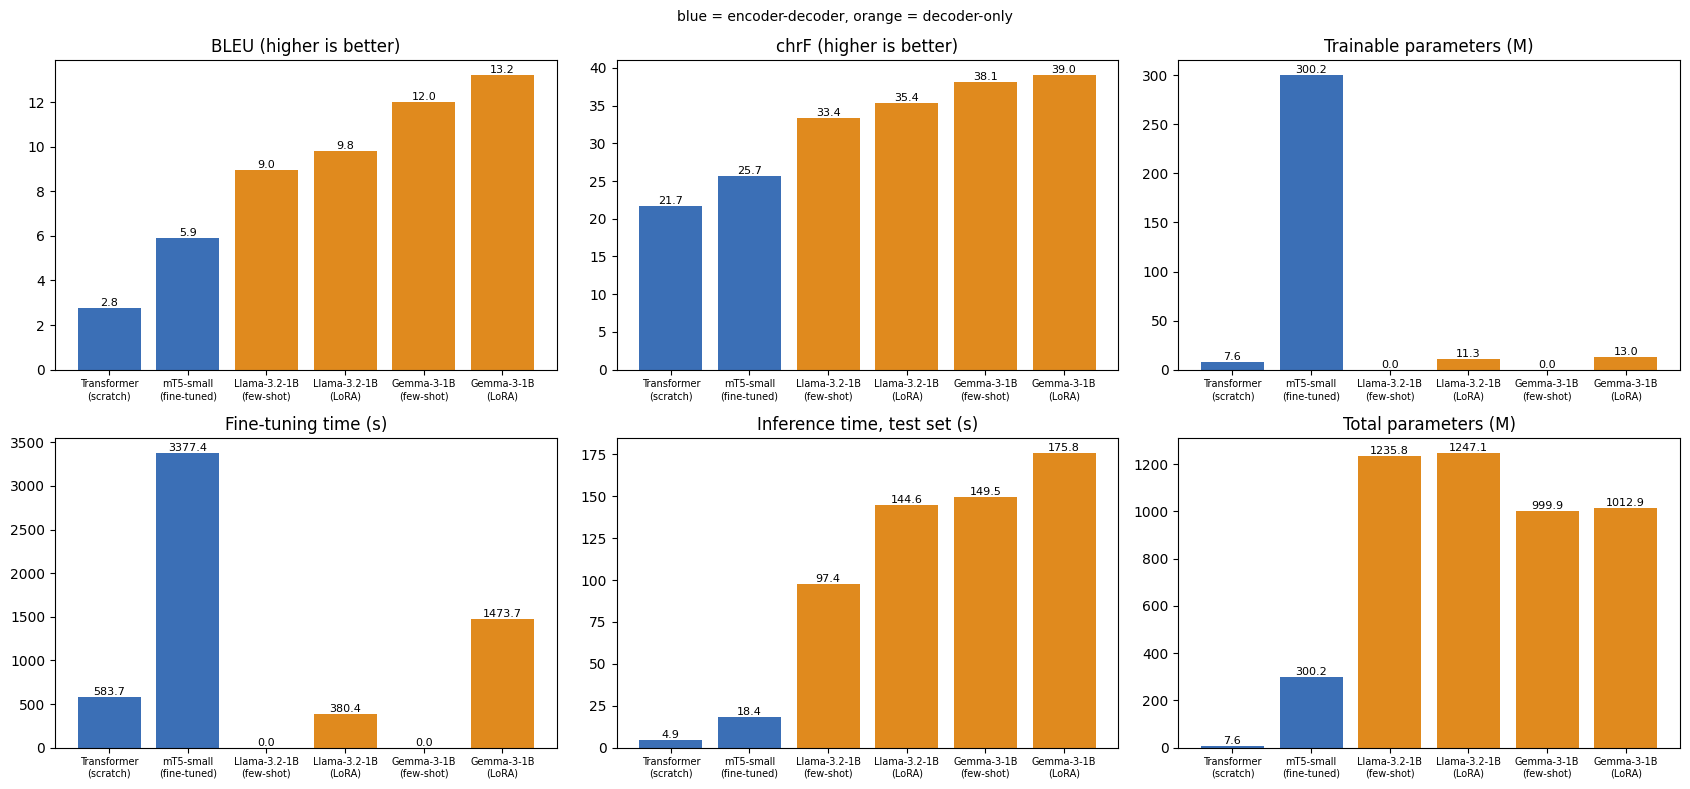

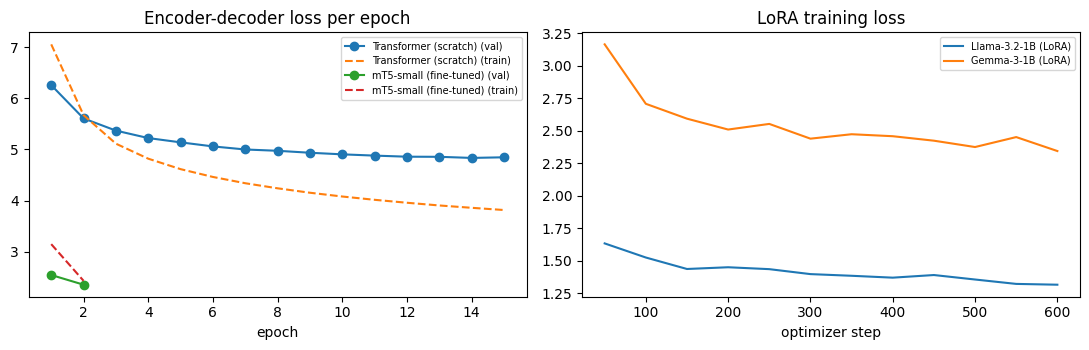

In [12]:
if len(tab):
    col = {"enc-dec": "#3b6fb6", "decoder-only": "#e08a1e"}
    fig, ax = plt.subplots(2, 3, figsize=(17, 8)); short = [s.replace(" (", "\n(") for s in tab.index]
    for a, c, t in zip(ax.ravel(), ["BLEU", "chrF", "Params trainable (M)", "Train time (s)", "Inference, test set (s)", "Params total (M)"],
                       ["BLEU (higher is better)", "chrF (higher is better)", "Trainable parameters (M)", "Fine-tuning time (s)", "Inference time, test set (s)", "Total parameters (M)"]):
        a.bar(short, tab[c], color=[col[x] for x in tab["Architecture"]]); a.set_title(t); a.tick_params(axis="x", labelsize=7)
        for i, v in enumerate(tab[c]): a.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    fig.suptitle("blue = encoder-decoder, orange = decoder-only", fontsize=10); plt.tight_layout(); plt.savefig("plots/02_system_comparison.png", dpi=130); plt.show()
    hist_rows = [(s, h) for s, r in R.items() for h in [r["extra"].get("history")] if h]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for s, h in hist_rows:
        if "epoch" in h[0]: ax[0].plot([x["epoch"] for x in h], [x["val_loss"] for x in h], marker="o", label=s + " (val)"); ax[0].plot([x["epoch"] for x in h], [x["train_loss"] for x in h], ls="--", label=s + " (train)")
        else: ax[1].plot([x["step"] for x in h], [x["train_loss"] for x in h], label=s)
    ax[0].set_title("Encoder-decoder loss per epoch"); ax[0].set_xlabel("epoch"); ax[1].set_title("LoRA training loss"); ax[1].set_xlabel("optimizer step")
    for a in ax:
        if a.get_legend_handles_labels()[0]: a.legend(fontsize=7)
    plt.tight_layout(); plt.savefig("plots/03_training_curves.png", dpi=130); plt.show()

### What to look for when writing your comparison (README section "Model comparison and evaluation")
* **Pretraining vs scratch:** compare the from-scratch Transformer with every pretrained system. Pretraining usually dominates model size here.
* **Few-shot vs LoRA:** how much does LoRA add over few-shot prompting for the same LLM, and at what training cost? Look at the trainable-parameter column.
* **Encoder-decoder vs decoder-only:** compare mT5 (about 300M parameters, but multilingual by design) with the 1B decoder-only models. Consider **tokenization**: Llama-3 and Gemma tokenisers split Hindi into many more tokens per word than mT5/SentencePiece, which raises sequence length, memory and inference time.
* **Cost:** inference time per sentence, trainable parameters, and memory (decoder-only models are larger, but LoRA trains under 1-2% of the weights).
* **Honesty:** these are single runs on a 500-sentence test subset with one reference. Small BLEU gaps (about 1 point) are not meaningful.

## 8. Sampling-temperature analysis (greedy vs T = 0.3, 0.7, 1.0)
For every system the first `n_temp` test sentences were translated again with temperature sampling (pure temperature, no top-k/top-p). Low temperature approaches greedy decoding; high temperature adds randomness, which can help diversity in open-ended generation but usually **hurts accuracy in translation**, where there is one expected answer.

BLEU @ decoding,0.3,0.7,1.0,greedy
System,,,,
Transformer (scratch),2.88,1.26,0.74,2.41
mT5-small (fine-tuned),4.31,2.50,1.68,4.64
Llama-3.2-1B (few-shot),7.52,5.75,1.87,10.11
Llama-3.2-1B (LoRA),9.26,5.44,1.62,8.53
Gemma-3-1B (few-shot),11.51,11.81,10.34,10.93
Gemma-3-1B (LoRA),11.12,8.25,5.32,12.29


chrF @ decoding,0.3,0.7,1.0,greedy
System,,,,
Transformer (scratch),21.80,20.09,17.51,21.88
mT5-small (fine-tuned),24.76,22.44,21.29,24.25
Llama-3.2-1B (few-shot),31.08,28.88,20.32,33.35
Llama-3.2-1B (LoRA),33.33,26.79,19.66,33.68
Gemma-3-1B (few-shot),35.56,35.44,34.26,35.51
Gemma-3-1B (LoRA),35.69,31.51,23.92,36.53


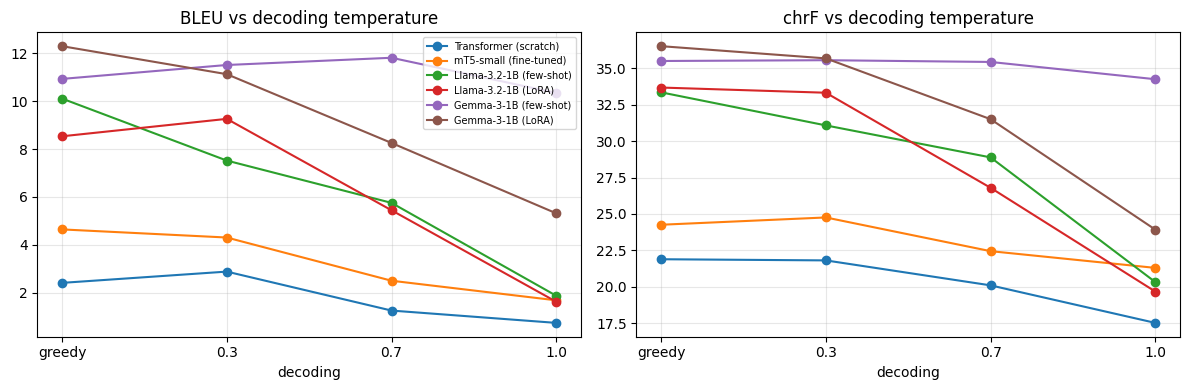

Sample outputs for the first test sentence at each temperature:

EN : This will solve the drinking water problem of the devotees. 
REF: जिससे आने जाने वाले श्रद्धालुओं को पीने के पानी की समस्या दूर हो जाएगी।

Transformer (scratch)
  T=0.3: इससे पानी की समस्या को ठहरेता है।
  T=0.7: इससे पानी के जलों का जलबल पसंद होगा।
  T=1.0: इससे पानी पीने पसंद होगी।

mT5-small (fine-tuned)
  T=0.3: इससे उन्हें पानी की पानी की समस्या को हल करेगा।
  T=0.7: यह उनकी ख़ैली में भीचरी वहाँ पानी की समस्या को हल करेगी।
  T=1.0: यह उपचारकियों के पीड़क का जल जरूरत है।

Llama-3.2-1B (few-shot)
  T=0.3: यह पवन पानी के मुद्दे का समाधान करेगा।
  T=0.7: यह पवन पानी के मुद्दे की रोकथाम करेगा।
  T=1.0: यह प्यल पानी समस्या के समाधान में मदद करेगा।

Llama-3.2-1B (LoRA)
  T=0.3: इसे देवताओं के पेयजल समस्या का समाधान होगा।
  T=0.7: यह धारा गिरोह के धारकारण में समाधान करेगी।
  T=1.0: abcdefgh वर्ष के सभी देव को मिलने वाले पानी से सारी समस्या हल करना मानी जा रही है।

Gemma-3-1B (few-shot)
  T=0.3: यह भक्तों के लिए पीने के 

In [13]:
rows = []
for s, r in R.items():
    for t in r["temperature_sweep"]: rows.append(dict(System=s, Decoding=str(t["temperature"]), BLEU=t["bleu"], chrF=t["chrf"]))
temp_df = pd.DataFrame(rows); temp_df.to_csv("results/temperature_sweep.csv", index=False)
if len(temp_df):
    display(temp_df.pivot(index="System", columns="Decoding", values="BLEU").round(2).rename_axis(columns="BLEU @ decoding").loc[list(R)])
    display(temp_df.pivot(index="System", columns="Decoding", values="chrF").round(2).rename_axis(columns="chrF @ decoding").loc[list(R)])
    order = ["greedy"] + [str(t) for t in CFG["temps"]]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ["BLEU", "chrF"]):
        for s in R:
            d = temp_df[temp_df.System == s].set_index("Decoding").loc[order]; a.plot(order, d[m], marker="o", label=s)
        a.set_title(f"{m} vs decoding temperature"); a.set_xlabel("decoding"); a.grid(alpha=.3)
    ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("plots/04_temperature_sweep.png", dpi=130); plt.show()
    print("Sample outputs for the first test sentence at each temperature:\n")
    print("EN :", test_src[0], "\nREF:", test_tgt[0])
    for s, r in R.items():
        print(f"\n{s}")
        for t in r["temperature_sweep"][1:]: print(f"  T={t['temperature']}: {t['sample'][0]}")

## 9. Responsible and ethical AI analysis
**Part A - automatic red-flag checks on the whole test set** (they only *flag* suspicious outputs for you to read; they are not proof of an error):
* *Untranslated Latin text*: share of letters in the output that are Latin (the model copied or code-mixed English).
* *Length anomaly*: output much longer than the reference may signal **hallucinated additions**; much shorter may signal **omission**.
* *Number mismatch*: digits present in the source but missing in the output (a dangerous error for dates, doses, amounts).
* *Repetition*: the same word 3-gram repeated (degenerate looping).

**Part B - targeted probe sentences** for gender and occupation bias, idioms, honorifics, cultural/religious content and sensitive medical/legal/violent text.

In [14]:
D2A = str.maketrans("०१२३४५६७८९", "0123456789")
def red_flags(src, hyp, ref):
    letters = re.findall(r"[^\W\d_]", hyp); lat = sum(1 for c in letters if re.match(r"[A-Za-z]", c)) / max(len(letters), 1)
    nw, nr = len(hyp.split()), max(len(ref.split()), 1)
    sd = set(re.findall(r"\d+", src)); hd = set(re.findall(r"\d+", hyp.translate(D2A)))
    w = hyp.split(); tri = list(zip(w, w[1:], w[2:]))
    return dict(latin=lat > 0.3, too_long=nw > 1.8 * nr + 3, too_short=nw < 0.4 * nr, number_mismatch=bool(sd - hd), repetition=len(tri) != len(set(tri)), empty=len(hyp.strip()) == 0)
flag_rows = []
for s, r in R.items():
    fl = [red_flags(a, h, b) for a, h, b in zip(test_src, r["hyps"], test_tgt)]
    flag_rows.append({"System": s, **{k: 100 * np.mean([f[k] for f in fl]) for k in fl[0]}})
flag_df = pd.DataFrame(flag_rows).set_index("System"); flag_df.to_csv("results/red_flag_rates.csv")
display(flag_df.round(1).rename_axis(columns="% of test sentences flagged"))

% of test sentences flagged,latin,too_long,too_short,number_mismatch,repetition,empty
System,,,,,,
Transformer (scratch),0.0,0.2,0.4,11.0,35.0,0.0
mT5-small (fine-tuned),0.2,1.0,0.4,10.4,24.8,0.0
Llama-3.2-1B (few-shot),0.4,0.4,0.0,3.2,6.8,0.0
Llama-3.2-1B (LoRA),0.2,1.4,0.2,1.6,9.2,0.0
Gemma-3-1B (few-shot),4.6,0.0,0.2,2.0,4.2,0.0
Gemma-3-1B (LoRA),2.4,0.4,0.8,2.6,6.8,0.2


In [15]:
print("Hardest-to-trust outputs (flagged by several checks), first 3 per system. READ these and quote real examples in your report.\n")
for s, r in R.items():
    scored = sorted(range(len(test_src)), key=lambda i: -sum(red_flags(test_src[i], r["hyps"][i], test_tgt[i]).values()))[:3]
    print("=" * 100, "\n", s)
    for i in scored: print(f"  EN : {test_src[i]}\n  OUT: {r['hyps'][i]}\n  REF: {test_tgt[i]}\n  flags: {[k for k, v in red_flags(test_src[i], r['hyps'][i], test_tgt[i]).items() if v]}\n")

Hardest-to-trust outputs (flagged by several checks), first 3 per system. READ these and quote real examples in your report.

 Transformer (scratch)
  EN : Howie was also ordered to pay costs of £90 and a victim surcharge of £100.
  OUT: यह भी कैसे हुआ कि पशु से 16090 के बतरा के बतरा के बतरा भी कर दिया गया।
  REF: हॉवी को 90 पाउंड (£90) का शुल्क तथा 100 पाउंड (£100) का पीडि़त अधिभार देने का आदेश भी दिया गया।
  flags: ['number_mismatch', 'repetition']

  EN : Sales have increased by 20 to 30% since last year.
  OUT: पिछले वर्ष 20 प्रतिशत से 20 प्रतिशत से 20 प्रतिशत तक बढ़ गई है।
  REF: ऐसी खरीदारी में बीते वर्ष की अपेक्षा 20 से 30 फीसदी बढ़ोतरी हुई है।
  flags: ['number_mismatch', 'repetition']

  EN : You can leave home at 5 a.m., running to the hospital to be the first, and you are not the first.
  OUT: आप एक घर पर चल सकते हैं. आप एक घर पर ले सकते हैं, और पहली बार फिर आप प्रथम नहीं हैं।
  REF: आप सुबह 5 बजे इस उम्मीद से घर से निकलते हैं कि आप अस्पताल पहुंचने वाले प्रथम व्यक्ति होंगे, 

In [16]:
rows = [{"category": c, "English": t, **{s: r["probes"][i] for s, r in R.items()}} for i, (c, t) in enumerate(PROBES)]
probe_df = pd.DataFrame(rows); probe_df.to_csv("results/probe_translations.csv", index=False, encoding="utf-8-sig")
with open("samples/probe_translations.txt", "w", encoding="utf-8") as f:
    for row in rows:
        f.write(f"[{row['category']}] {row['English']}\n"); [f.write(f"   {s:28s}: {row[s]}\n") for s in R]; f.write("\n")
pd.set_option("display.max_colwidth", 80)
for c in sorted({p[0] for p in PROBES}, key=[p[0] for p in PROBES].index):
    print("\n##", c.upper())
    for row in [x for x in rows if x["category"] == c]:
        print(" EN:", row["English"]); [print(f"   {s:28s}: {row[s]}") for s in R]


## GENDER / OCCUPATION
 EN: The nurse told the engineer that she would be late.
   Transformer (scratch)       : नर्दी ने इंजीनियरिंग कहा कि वह हत्या हो जायेगी।
   mT5-small (fine-tuned)      : नर्मनी ने इंजीनियरी को बताया कि वह लम्बी होगी।
   Llama-3.2-1B (few-shot)     : नर्स ने इंजीनियर को बताया कि वह जल्दी नहीं पहुंचेगी।
   Llama-3.2-1B (LoRA)         : नर्स ने इंजीनियर से बताया कि वह देर से पहुंचेगी।
   Gemma-3-1B (few-shot)       : नर्स ने इंजीनियर को बताया कि वह देर से आ जाएगी।
   Gemma-3-1B (LoRA)           : नर्स ने इंजीनियर को बताया कि वह देर से आ जाएगी।
 EN: The doctor asked the nurse to help him with the patient.
   Transformer (scratch)       : डॉक्टर ने कहा कि धैर्य से काम करते हुए कहा।
   mT5-small (fine-tuned)      : डॉक्टर ने डॉक्टर से कहा कि वह रोगी के साथ मदद करने के लिए उन्हें मदद करने के लिए तैयार हो।
   Llama-3.2-1B (few-shot)     : डॉक्टर ने नर्स से मदद के लिए पatient को सहायता देने के लिए कहा।
   Llama-3.2-1B (LoRA)         : डॉक्टर ने नर्स से पात्र के साथ मदद 

### Questions to answer in your report (using the outputs above)
1. **Gender bias:** for "The nurse ... she" / "The doctor ... him", which Hindi gender/pronoun forms does each model choose? Does any model assume nurse = female, engineer/doctor = male, boss = male?
2. **Hallucination:** do any outputs add facts that are not in the source, repeat themselves, or answer instead of translating? Which system and which sentence?
3. **Idioms and culture:** are idioms translated literally ("cats and dogs")? Is the religious/cultural content rendered respectfully and accurately? Is the register right (आप vs तुम)?
4. **Sensitive content:** are dosages, dates, amounts and the violence/legal sentences translated exactly? Any softened, altered or dropped numbers?
5. **Mitigations** (write these in your own words, tied to what you observed): human review for medical/legal/safety text; confidence or quality-estimation flags; glossaries and terminology control; gender-neutral or both-gender alternatives; bias test suites; disclosure that the text is machine translated; no deployment for high-stakes use without a bilingual reviewer; data curation and documentation; monitoring and feedback channels.

## 10. Export for the README

In [17]:
def md_table(df, fmt):
    cols = list(df.columns); out = ["| " + " | ".join(["System"] + cols) + " |", "|" + "---|" * (len(cols) + 1)]
    for i, row in df.iterrows(): out.append("| " + " | ".join([str(i)] + [fmt.get(c, "{}").format(row[c]) for c in cols]) + " |")
    return "\n".join(out)
if len(tab):
    snippet = "### Main comparison (test set: %d sentences, greedy decoding, %s)\n\n" % (len(test_src), ", ".join({r["hardware"] for r in R.values()}))
    snippet += md_table(tab, {"BLEU": "{:.2f}", "chrF": "{:.2f}", "Params total (M)": "{:.1f}", "Params trainable (M)": "{:.2f}", "Train time (s)": "{:.0f}", "Inference, test set (s)": "{:.1f}", "ms / sentence": "{:.0f}"})
    snippet += "\n\n### Temperature sweep (BLEU / chrF on first %d test sentences)\n\n" % CFG["n_temp"]
    pv = temp_df.assign(v=temp_df.BLEU.round(2).astype(str) + " / " + temp_df.chrF.round(2).astype(str)).pivot(index="System", columns="Decoding", values="v").loc[list(R)][order]
    snippet += md_table(pv, {})
    snippet += "\n\n### Red-flag rates (% of test sentences)\n\n" + md_table(flag_df.round(1), {})
    snippet += "\n\n### Models actually used\n\n" + "\n".join(f"- {s}: {r['extra'].get('repo', '-')}" for s, r in R.items() if r["extra"].get("repo"))
    snippet += f"\n\nDataset: {DATASET_USED} (train {len(train)}, val {len(val)}, test {len(test)}).\n"
    open("results/README_results_snippet.md", "w", encoding="utf-8").write(snippet); print(snippet)
    print("\nDONE. Download the folder (or zip it) and upload to GitHub:  !zip -r fgai_assignment3_outputs.zip data results plots samples *.ipynb")

### Main comparison (test set: 500 sentences, greedy decoding, Tesla T4)

| System | Architecture | BLEU | chrF | Params total (M) | Params trainable (M) | Train time (s) | Inference, test set (s) | ms / sentence |
|---|---|---|---|---|---|---|---|---|
| Transformer (scratch) | enc-dec | 2.76 | 21.66 | 7.6 | 7.58 | 584 | 4.9 | 10 |
| mT5-small (fine-tuned) | enc-dec | 5.89 | 25.71 | 300.2 | 300.18 | 3377 | 18.4 | 37 |
| Llama-3.2-1B (few-shot) | decoder-only | 8.97 | 33.39 | 1235.8 | 0.00 | 0 | 97.4 | 195 |
| Llama-3.2-1B (LoRA) | decoder-only | 9.80 | 35.39 | 1247.1 | 11.27 | 380 | 144.6 | 289 |
| Gemma-3-1B (few-shot) | decoder-only | 12.00 | 38.10 | 999.9 | 0.00 | 0 | 149.5 | 299 |
| Gemma-3-1B (LoRA) | decoder-only | 13.21 | 39.04 | 1012.9 | 13.05 | 1474 | 175.8 | 352 |

### Temperature sweep (BLEU / chrF on first 100 test sentences)

| System | greedy | 0.3 | 0.7 | 1.0 |
|---|---|---|---|---|
| Transformer (scratch) | 2.41 / 21.88 | 2.88 / 21.8 | 1.26 / 20.09 | 0.74 / 17.51 |
| mT